# Домашнее задание. Занятие 11. Мидтерм, этап 1: от сырого файла к чистой таблице

**DataGroup. Курс AI Engineering. Неделя 6**

Это тетрадь вашего мидтерм-проекта. На этапе 1 (домашка занятия 11) вы заполняете разделы 0-9: выбираете датасет и доводите его до чистой таблицы с EDA. На этапе 2 (домашка занятия 12, сам мидтерм) продолжаете **эту же тетрадь**, разделы 10-16: признаки, утечка, baseline и README. Полное ТЗ с критериями и списком датасетов в файле `Midterm_TZ.md`.

**Как работать с тетрадью**

1. Откройте её в Google Colab: «Файл», затем «Загрузить блокнот». Сразу переименуйте в `project.ipynb`: под этим именем она будет лежать в репозитории.
2. **Первой запустите ячейку «Помощники»** ниже. Если перезапустили среду, запустите её снова.
3. Идите по разделам сверху вниз. В каждом разделе есть **«Что сделать»**, ссылка на часть тетради практики занятия 11, где это показано на отелях, пустые ячейки для кода и ячейка **«Вывод»**: её заполняете своими словами.
4. Каждое решение про данные записывайте в журнал: `log("шаг", "что решили", len(df))`.
5. В конце этапа запустите самопроверку (раздел 9), потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти без ошибок.
6. Загрузите тетрадь и файлы в публичный репозиторий на GitHub и сдайте **ссылку на репозиторий** в LMS. Как загрузить, в разделе 9 и в ТЗ.

**Баллы этапа 1: 100.**

| раздел | баллы |
|---|---|
| 0-1. Карточка проекта и первый взгляд | 10 |
| 2-3. Дубли и невозможные значения | 15 |
| 4. Пропуски | 20 |
| 5-6. Типы, даты и выбросы | 15 |
| 7. EDA: 5 графиков с выводами | 20 |
| 8. Функция `clean`, сторожа, журнал, чистый CSV | 10 |
| 9. Репозиторий: публичный, тетрадь с выводами | 10 |

**Данные.** Один датасет из списка в ТЗ или свой, согласованный в чате группы. Вот список коротко, ссылки и подробности в ТЗ:

| датасет | задача | уровень |
|---|---|---|
| клиенты телеком-компании (Telco) | классификация: уйдёт ли клиент | базовый |
| поездки на такси в Нью-Йорке | регрессия: чаевые или стоимость | базовый |
| рейтинги шоколада | регрессия: оценка плитки | базовый |
| банк: телемаркетинг вкладов | классификация: откроет ли вклад | средний |
| восхождения в Гималаях | классификация: дойдёт ли до вершины | средний |
| Airbnb в Нью-Йорке | регрессия: цена ночи | средний |
| песни Spotify | регрессия: популярность трека | средний |
| мебель IKEA | регрессия: цена | средний |
| оценки кофе | регрессия: итоговая оценка | продвинутый |
| дома в Эймсе | регрессия: цена дома | продвинутый |

**Как устроено.** Проверки с баллами здесь нет: работу проверяет преподаватель по критериям из ТЗ. Решения принимаете вы, и главное в каждом разделе не код, а **вывод**: что вы увидели и почему решили именно так. Короткий честный вывод лучше длинного пересказа кода.

**Чем пользоваться.** Помощники ниже: `load_csv`, `passport`, `log` и `show_journal`, `target_plot`, `selfcheck`. Всё остальное из тетради практики занятия 11: её функции можно копировать и менять под свои данные.

**Если застряли.** Каждый раздел ссылается на часть тетради практики, где то же самое сделано на отелях. Задайте вопрос в чате группы, не дожидаясь срока. И ставьте `print` после каждого шага: почти всегда окажется, что в таблице лежит не то, что вы думали.

---
## Помощники

Запустите эту ячейку первой. Она подключает библиотеки и создаёт пять функций для проекта.

In [276]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


---
# Этап 1. Домашка занятия 11

---
## 0. Карточка проекта  ·  вместе с разделом 1: 10 баллов

**Что сделать.** Заполните таблицу ниже (двойной щелчок по ячейке) и укажите ссылку и цель в коде. Пример карточки: часть 1 тетради практики, раздел 1.1.

| вопрос | ответ |
|---|---|
| датасет и ссылка на источник | ... |
| что значит одна строка | ... |
| цель (столбец) | ... |
| тип задачи | классификация или регрессия |
| метрика | доля верных ответов или MAE |
| кому и зачем нужен такой прогноз | ... |

In [277]:
DATA_URL = "https://raw.githubusercontent.com/madmashup/targeted-marketing-predictive-engine/master/banking.csv"   # прямая ссылка на CSV из ТЗ или на свой файл
TARGET = "y"     # имя столбца-цели

---
## 1. Первый взгляд

**Что сделать.**

* загрузить данные: `raw = load_csv(DATA_URL)`, посмотреть `shape` и `head`;
* паспорт данных: `passport(raw)`;
* распределение цели: для класса `value_counts()`, для числа `describe()` и гистограмма;
* если цель текстом («Yes» и «No»), превратить её в 0 и 1, например `(raw[TARGET] == "Yes").astype(int)`, и записать это в журнал.

Пример: часть 1 практики, разделы 1.1-1.4.

In [278]:
# загрузка, shape, head
raw = load_csv(DATA_URL)
print("Размер таблицы:", raw.shape)
raw.head()

Размер таблицы: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,210,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,0
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,138,1,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,0
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,339,3,6,2,success,-1.7,94.055,-39.8,0.729,4991.6,1
3,39,services,married,high.school,no,no,no,cellular,apr,fri,185,2,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,0
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,137,1,3,1,success,-2.9,92.201,-31.4,0.869,5076.2,1


In [279]:
# паспорт данных
passport(raw)

,тип,пропусков,"доля, %",разных,пример
age,int64,0,0.0,78,44
job,object,0,0.0,12,blue-collar
marital,object,0,0.0,4,married
education,object,0,0.0,8,basic.4y
default,object,0,0.0,3,unknown
housing,object,0,0.0,3,yes
loan,object,0,0.0,3,no
contact,object,0,0.0,2,cellular
month,object,0,0.0,10,aug
day_of_week,object,0,0.0,5,thu


In [280]:
# цель: распределение, при необходимости в числа 0 и 1
print("Количество записей:")
print(raw[TARGET].value_counts().sort_index())

print("\n Доля в процентах:")
print((raw[TARGET].value_counts(normalize=True).sort_index() * 100).round(2))

Количество записей:
y
0    36548
1     4640
Name: count, dtype: int64

 Доля в процентах:
y
0    88.73
1    11.27
Name: proportion, dtype: float64


**Вывод.** Сколько строк и столбцов, какие проблемы видны в паспорте (текст вместо чисел, пропуски, странное число разных значений), как распределена цель.

В таблице 41 188 строк и 21 столбец. Есть числовые и текстовые признаки. Обычных пропусков нет, но встречается значение unknown. Цель уже имеет значения 0 и 1. Классы несбалансированы: вклад открыли около 11,27% клиентов.

---
## 2. Дубли  ·  вместе с разделом 3: 15 баллов

**Что сделать.**

* сколько полных дублей: `raw.duplicated().sum()`;
* если в данных есть номер записи (id), то и повторы по нему: `duplicated(subset=["..."])`;
* посмотреть на несколько дублей глазами (`keep=False`) и решить, что это: ошибка выгрузки, одна запись в нескольких местах или разные настоящие строки;
* записать решение в журнал.

Пример: часть 2 практики, разделы 2.1-2.4.

In [281]:
# сколько дублей, какие они
print("Количество полных дублей:", raw.duplicated().sum())

duplicates = raw[raw.duplicated(keep=False)]
duplicates.head(10)

Количество полных дублей: 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
4601,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,0
8178,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,0
8988,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,0
11725,45,admin.,married,university.degree,no,no,no,cellular,jul,thu,252,1,999,0,nonexistent,-2.9,92.469,-33.6,1.072,5076.2,1
12041,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,0
13488,71,retired,single,university.degree,no,no,no,telephone,oct,tue,120,1,999,0,nonexistent,-3.4,92.431,-26.9,0.742,5017.5,0
17501,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,0
17954,41,technician,married,professional.course,no,yes,no,cellular,aug,tue,127,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,0
17977,41,technician,married,professional.course,no,yes,no,cellular,aug,tue,127,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,0
19339,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,0


In [282]:
# решение: df = ... ; log(...)
df = raw.drop_duplicates().copy()

log("дубли", "Удалены полные повторы строк", len(df))

print("До удаления:", raw.shape)
print("После удаления:", df.shape)

До удаления: (41188, 21)
После удаления: (41176, 21)


**Вывод.** Сколько дублей, что это по смыслу и почему решили удалить или оставить.

Найдено 12 полных повторов строк. Без ID клиента нельзя точно установить причину повторения. Решено удалить полные повторы до разделения данных, чтобы одинаковые записи не попали одновременно в train и test. Осталось 41 176 строк.

---
## 3. Невозможные значения и скрытые пропуски

**Что сделать.**

* написать функцию `check_rules(d)`, которая возвращает таблицу флагов: минимум 3 правила здравого смысла (отрицательная цена, ноль там, где ноль невозможен, возраст 150 лет);
* посмотреть на нарушителей глазами и решить по каждому правилу: удалить, исправить или оставить;
* найти скрытые пропуски: `value_counts()` по текстовым столбцам, `describe()` по числовым. Ищите `unknown`, `Undefined`, `?`, пробел, `999`, нули там, где их не бывает;
* записать решения в журнал.

Пример: часть 2 практики, разделы 2.5-2.7.

In [283]:
def check_rules(d):
    """Таблица флагов: True там, где строка нарушает правило."""
    return pd.DataFrame({
        # "название правила": условие,
        "Подозрительный возраст": (d["age"] <= 0) | (d["age"] > 100),
        "campaign меньше одного": d["campaign"] < 1,
        "previous меньше 0": d["previous"] < 0,
        "duration меньше 0": d["duration"] < 0,
        "pdays меньше 0": d["pdays"] < 0,
        "неожиданное значение housing": ~d["housing"].isin(["yes", "no", "unknown"]),
        "неожиданное значение loan": ~d["loan"].isin(["yes", "no", "unknown"]),
        "неожиданное значение default": ~d["default"].isin(["yes", "no", "unknown"])
    }, index=d.index)

In [284]:
# сколько нарушений по каждому правилу, нарушители глазами
flags = check_rules(df)

print("Количество нарушении:")
print(flags.sum())

bad_rows = flags.any(axis=1)
print("\nПодозрительных строк:", bad_rows.sum())

display(df.loc[bad_rows].head(10))

Количество нарушении:
Подозрительный возраст          0
campaign меньше одного          0
previous меньше 0               0
duration меньше 0               0
pdays меньше 0                  0
неожиданное значение housing    0
неожиданное значение loan       0
неожиданное значение default    0
dtype: int64

Подозрительных строк: 0


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y


In [285]:
# скрытые пропуски: value_counts и describe
text_columns = df.select_dtypes(include=["object", "string"]).columns

for column in text_columns:
  print("\nСтолбец:", column)
  print(df[column].value_counts(dropna=False))

display(df.describe().T)

print("\nКоличество pdays == 999:")
print((df["pdays"] == 999).sum())


Столбец: job
job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

Столбец: marital
marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64

Столбец: education
education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64

Столбец: default
default
no         32577
unknown     8596
yes            3
Name: count, dtype: int64

Столбец: housing
housing
yes        21571
no         18615
unknown      990
Name: count, dtype: int64

Столбец: loan
loan
no         33938
yes         6248
unknown 

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp_var_rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons_price_idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons_conf_idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr_employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100



Количество pdays == 999:
39661


In [286]:
# решения и журнал
log(
    "проверка правил",
    f"найдено подозрительных строк: {int(bad_rows.sum())}. Строки сохранены.",
    len(df)
)

log(
    "скрытые пропуски",
    "unknown сохранены как категории. nonexistent сохранён. "
    "pdays==999 будет обработан при создании признаков.",
    len(df)
)

**Вывод.** Какие правила, сколько нарушений, что удалили или исправили и почему. Какие скрытые пропуски нашли.

Нарушений по выбранным правилам не найдено. Обнаружены скрытые пропуски unknown и специальный код pdays=999. Строки с ними сохранены: unknown остаётся категорией, а pdays=999 будет отдельно обработан при создании признаков. Значение nonexistent означает отсутствие предыдущей кампании и также сохраняется.

---
## 4. Пропуски  ·  20 баллов

**Что сделать.**

* для каждого столбца с пропусками сравнить цель у строк с пропуском и без: `df.groupby(df[col].isna())[TARGET].mean()`;
* решить, что значит пропуск: «не знаем» или «нет»;
* заполнить: «нет» по смыслу (0, «нет»), «не знаем» медианой, самым частым или категорией `Unknown`; если пропуск говорит о строке, сначала флаг; если пропусков больше половины, флаг и удалить столбец;
* заполнить таблицу решений ниже и записать решения в журнал.

По желанию, без баллов: проверить способ заполнения на известных значениях, как в разделе 3.4 практики.

Пример: часть 3 практики.

In [287]:
# где пропуски и сколько
nan_count = df.isna().sum()
unknown_count = df.eq("unknown").sum()

missing_report = pd.DataFrame({
    "NaN": nan_count,
    "unknown": unknown_count
})

missing_report["Всего неизвестных"] = nan_count + unknown_count
missing_report["Доля неизвестных, %"] = (
    missing_report["Всего неизвестных"] / len(df) * 100
).round(2)


display(missing_report[missing_report["Всего неизвестных"] > 0].sort_values("Доля неизвестных, %", ascending=False))

print("Записей с pdays = 999:", (df["pdays"] == 999).sum())

,NaN,unknown,Всего неизвестных,"Доля неизвестных, %"
default,0,8596,8596,20.88
education,0,1730,1730,4.20
housing,0,990,990,2.40
loan,0,990,990,2.40
job,0,330,330,0.80
marital,0,80,80,0.19


Записей с pdays = 999: 39661


In [288]:
# пропуск как информация: цель у строк с пропуском и без
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.2,
    random_state=42,
    stratify=df[TARGET]
)

analysis_df = df.loc[train_idx].copy()

missing_columns = missing_report.index[
    missing_report["Всего неизвестных"] > 0
]

for column in missing_columns:
  is_missing = (
      analysis_df[column].isna() | analysis_df[column].eq("unknown")
  )

  result = analysis_df.groupby(is_missing)[TARGET].agg(["count", "mean"])

  result.index = result.index.map({
    False: "Информация известна",
    True: "Информация неизвестна"
  })

  result["Доля открывших вклад, %"] = (result["mean"] * 100).round(2)
  print("\nСтолбец:", column)
  display(result[["count", "Доля открывших вклад, %"]])



Столбец: job


,count,"Доля открывших вклад, %"
job,,
Информация известна,32675,11.26
Информация неизвестна,265,12.08



Столбец: marital


,count,"Доля открывших вклад, %"
marital,,
Информация известна,32876,11.25
Информация неизвестна,64,17.19



Столбец: education


,count,"Доля открывших вклад, %"
education,,
Информация известна,31558,11.11
Информация неизвестна,1382,14.83


... (2 outputs left out)


Столбец: housing


,count,"Доля открывших вклад, %"
housing,,
Информация известна,32121,11.28
Информация неизвестна,819,10.62



Столбец: loan


,count,"Доля открывших вклад, %"
loan,,
Информация известна,32121,11.28
Информация неизвестна,819,10.62


In [289]:
# заполнение и журнал
df["was_previously_contacted"] = (df["pdays"] != 999).astype(int)
df["days_since_contact"] = df["pdays"].replace(999, np.nan)

log(
    "категориальные данные",
    "unknown сохранён отдельной категорией",
    len(df)
)

log(
    "pdays",
    "Созданы флаг прошлого контакта и давность с NaN вместо 999. "
    "Числовое заполнение будет внутри Pipeline.",
    len(df)
)

display(
    df[["pdays", "was_previously_contacted", "days_since_contact"]].head(10)
)

analysis_df = df.loc[train_idx].copy()

,pdays,was_previously_contacted,days_since_contact
0,999,0,NaN
1,999,0,NaN
2,6,1,6.0
3,999,0,NaN
4,3,1,3.0
5,999,0,NaN
6,999,0,NaN
7,999,0,NaN
8,3,1,3.0
9,999,0,NaN


| столбец | пропусков | «не знаем» или «нет» | что делаем | почему |
|---|---:|---|---|---|
| job | 330 | Не знаем работу | Оставляем unknown отдельной категорией | Неизвестная работа не означает отсутствие работы |
| marital | 80 | Не знаем семейное положение | Оставляем unknown отдельной категорией | Нет оснований подставлять другое семейное положение |
| education | 1730 | Не знаем образование | Оставляем unknown отдельной категорией | Неизвестное образование не означает отсутствие образования |
| default | 8596 | Не знаем о наличии дефолта | Оставляем unknown отдельной категорией | Нельзя считать неизвестный ответ подтверждённым no |
| housing | 990 | Не знаем о жилищном кредите | Оставляем unknown отдельной категорией | Неизвестность не означает отсутствие кредита |
| loan | 990 | Не знаем о потребительском кредите | Оставляем unknown отдельной категорией | Неизвестность не означает отсутствие кредита |
| days_since_contact, созданный из pdays | 39661 | Нет прошлого контакта | Создаём флаг контакта; вместо 999 в новом столбце записываем NaN. Заполнение будет в Pipeline | Отсутствие контакта нужно отличать от контакта ноль дней назад |

**Вывод.** В исходном CSV обычных пропусков NaN не было, но неизвестные сведения записаны как unknown. Они сохранены отдельными категориями. Значение pdays=999 означает отсутствие прошлого контакта. Для него созданы флаг was_previously_contacted и столбец days_since_contact, где 999 заменено на NaN. Заполнение числовых пропусков будет выполняться внутри Pipeline по обучающим данным. Строки из-за пропусков не удалялись.

---
## 5. Типы и даты  ·  вместе с разделом 6: 15 баллов

**Что сделать.**

* числа, записанные текстом, превратить в числа: `pd.to_numeric(s, errors="coerce")`, и посмотреть, что попало в пропуски;
* текст с единицами («76%», «SR 1,385», «1800-2200») разобрать: `str.replace`, `str.extract`;
* даты превратить в даты: `pd.to_datetime`, и достать из них признаки: месяц, день недели, час, разницу дат;
* показать `dtypes` после исправлений.

Если в ваших данных нет ни дат, ни чисел текстом, напишите это в выводе: так тоже бывает.

Пример: часть 4 практики, разделы 4.1-4.3.

In [290]:
# числа текстом
print("Типы данных:")
print(df.dtypes)

text_columns = df.select_dtypes(include=["object", "string"]).columns

for column in text_columns:
  print("\nСтолбец:", column)
  print(df[column].unique())

Типы данных:
age                           int64
job                          object
marital                      object
education                    object
default                      object
housing                      object
loan                         object
contact                      object
month                        object
day_of_week                  object
duration                      int64
campaign                      int64
pdays                         int64
previous                      int64
poutcome                     object
emp_var_rate                float64
cons_price_idx              float64
cons_conf_idx               float64
euribor3m                   float64
nr_employed                 float64
y                             int64
was_previously_contacted      int64
days_since_contact          float64
dtype: object

Столбец: job
['blue-collar' 'technician' 'management' 'services' 'retired' 'admin.'
 'housemaid' 'unemployed' 'entrepreneur' 'self-employed' 'un

In [291]:
# даты
print("Месяцы контакта:")
print(df["month"].unique())

print("\nДни недели контакта:")
print(df["day_of_week"].unique())

log(
  "типы и даты",
  "Числа уже имеют числовые типы. Полной даты контакта нет. "
  "month и day_of_week оставлены категориями.",
  len(df)
)

Месяцы контакта:
['aug' 'nov' 'jun' 'apr' 'jul' 'may' 'oct' 'mar' 'sep' 'dec']

Дни недели контакта:
['thu' 'fri' 'tue' 'mon' 'wed']


**Вывод.** Что было записано не так и как исправили.

Числовые столбцы уже имеют числовые типы. Чисел, записанных текстом или вместе с единицами измерения, не обнаружено. Полной даты контакта в данных нет: известны только месяц и день недели. Эти столбцы оставлены категориальными. Восстановить точную дату и год по ним нельзя.

---
## 6. Выбросы

**Что сделать.**

* для главных числовых столбцов найти кандидатов в выбросы: граница IQR или процентили (`quantile(0.999)`);
* по каждому решить: ошибка (удалить или исправить) или редкость (оставить, обрезать `clip`, сжать `np.log1p`);
* для длинного хвоста показать гистограммы до и после логарифма;
* записать решения в журнал.

Пример: часть 4 практики, разделы 4.4-4.6.

In [292]:
# кандидаты в выбросы
outlier_columns = [
    "age",
    "campaign",
    "previous",
    "days_since_contact"
]

numbers = analysis_df[outlier_columns]

q1 = numbers.quantile(0.25)
q3 = numbers.quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_flags = (numbers < lower) | (numbers > upper)

outlier_report = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Нижняя граница": lower,
    "Верхняя граница": upper,
    "Кандидатов": outlier_flags.sum()
})

display(outlier_report)

display(
    numbers.loc[outlier_flags.any(axis=1)].head(10)
)

,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Кандидатов
age,32.0,47.0,15.0,9.5,69.5,377
campaign,1.0,3.0,2.0,-2.0,6.0,1921
previous,0.0,0.0,0.0,0.0,0.0,4528
days_since_contact,3.0,7.0,4.0,-3.0,13.0,65


,age,campaign,previous,days_since_contact
38271,28,4,1,NaN
9251,81,3,0,NaN
3745,26,35,0,NaN
41051,59,4,1,NaN
29321,34,7,0,NaN
24108,31,1,1,5.0
28168,28,1,1,12.0
21415,24,3,1,13.0
16894,36,10,0,NaN
606,37,1,1,NaN


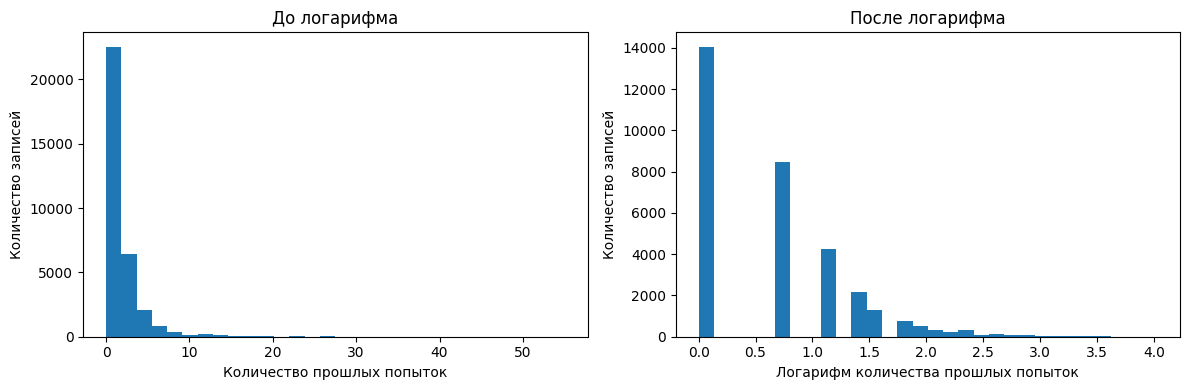

In [293]:
# решения: удалить, обрезать, логарифм
df["attempts_before_call_log"] = np.log1p(df["campaign"] - 1)

analysis_df = df.loc[train_idx].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(analysis_df["campaign"] - 1, bins=30)
axes[0].set_title("До логарифма")
axes[0].set_xlabel("Количество прошлых попыток")
axes[0].set_ylabel("Количество записей")

axes[1].hist(analysis_df["attempts_before_call_log"], bins=30)
axes[1].set_title("После логарифма")
axes[1].set_xlabel("Логарифм количества прошлых попыток")
axes[1].set_ylabel("Количество записей")

plt.tight_layout()
plt.show()

log(
    "выбросы",
    "Допустимые редкие значения сохранены. "
    "Для числа прошлых попыток создан логарифмический признак.",
    len(df)
)

**Вывод.** Какие выбросы нашли, что из них ошибки, а что настоящие редкости.

Метод IQR отметил редкие значения, но подтверждённых ошибок среди них не обнаружено. Допустимые значения возраста, истории и давности контактов сохранены. Для числа прошлых попыток создан логарифмический признак. Гистограммы показывают, как логарифм сжимает длинный хвост распределения. Строки по границам IQR не удалялись и не обрезались.

---
## 7. EDA: пять графиков  ·  20 баллов

**Что сделать.** Минимум 5 графиков. У каждого заголовок-вывод (не «lead_time и is_canceled», а «Чем раньше бронь, тем чаще отмена»), подписи осей с единицами и 1-3 предложения под графиком.

| график | на какой вопрос отвечает |
|---|---|
| распределение цели | какая доля классов или как распределено число |
| цель по 3-4 сильным признакам | что сильнее всего связано с целью |
| цель по времени или по группам | меняется ли картина по сезонам, городам, категориям |
| находка | что удивило: парадокс или подозрительно идеальный признак |

`target_plot(df, группы, TARGET, "заголовок-вывод", "подпись оси x")` рисует цель по группам. Числовой признак сначала разбейте на интервалы: `pd.cut(df["столбец"], [границы])`. Для двух числовых столбцов подойдёт `plt.scatter`.

Пример: часть 6 практики.

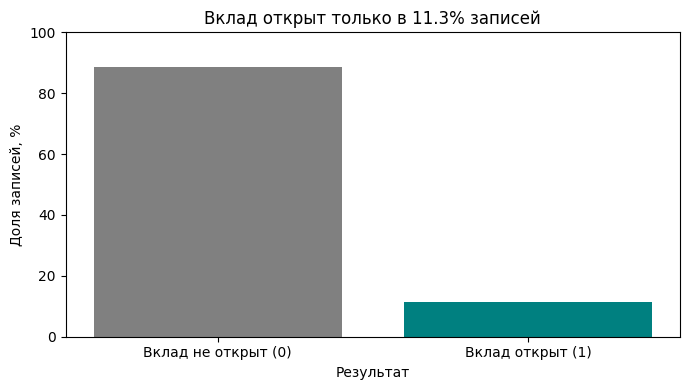

In [294]:
# график 1
target_share = analysis_df[TARGET].value_counts(normalize=True).sort_index() * 100

positive_share = target_share.loc[1]

plt.figure(figsize=(7, 4))

plt.bar(
    ["Вклад не открыт (0)", "Вклад открыт (1)"],
    target_share.values,
    color=["gray", "teal"]
)

plt.title(f"Вклад открыт только в {positive_share:.1f}% записей")
plt.xlabel("Результат")
plt.ylabel("Доля записей, %")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

Вклад открыт примерно в 11,3% записей обучающей части, поэтому классы несбалансированы. Постоянный ответ «вклад не открыт» уже даст около 88,7% правильных ответов, но пропустит все положительные случаи. Поэтому качество модели нужно сравнивать с пустышкой и дополнительно оценивать, сколько положительных случаев она находит.

**Что видно на графике 1.** ...

,count,mean
poutcome,,
nonexistent,28412,0.087709
failure,3404,0.142479
success,1124,0.653025


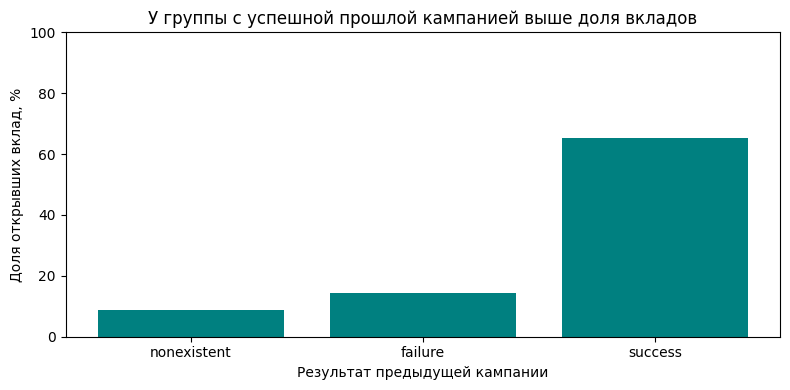

In [295]:
# график 2
outcome_stats = analysis_df.groupby("poutcome")[TARGET].agg(["count", "mean"]).sort_values("mean")
display(outcome_stats)

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    outcome_stats.index,
    outcome_stats["mean"] * 100,
    color="teal"
)

ax.set_title("У группы с успешной прошлой кампанией выше доля вкладов")
ax.set_xlabel("Результат предыдущей кампании")
ax.set_ylabel("Доля открывших вклад, %")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

В группе с успешной предыдущей кампанией доля открывших вклад составляет около 65%, а при отсутствии предыдущей кампании — около 9%. История прошлой кампании связана с текущим результатом и может быть полезна модели. Это наблюдаемая связь, а не доказательство причинного влияния.

**Что видно на графике 2.** ...

,count,mean
contact,,
telephone,12042,0.051819
cellular,20898,0.147717


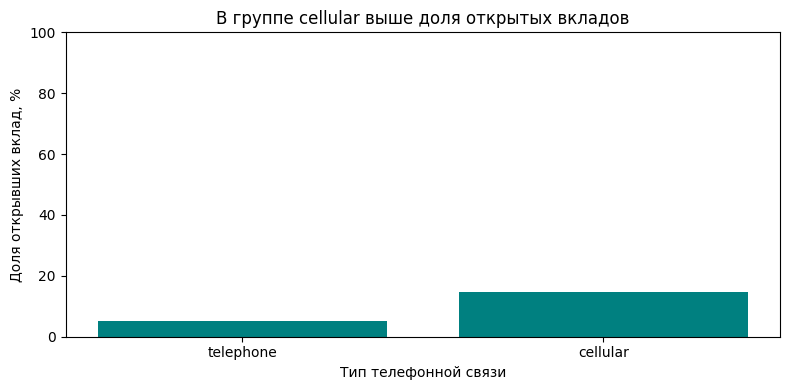

In [296]:
# график 3
contact_stats = analysis_df.groupby("contact")[TARGET].agg(["count", "mean"]).sort_values("mean")

display(contact_stats)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    contact_stats.index,
    contact_stats["mean"] * 100,
    color="teal"
)

ax.set_title("В группе cellular выше доля открытых вкладов")
ax.set_xlabel("Тип телефонной связи")
ax.set_ylabel("Доля открывших вклад, %")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

В группе cellular доля открывших вклад выше, чем в группе telephone. Тип связи может быть полезным признаком для модели. Однако это сравнение не доказывает, что смена типа связи сама увеличит отклик: группы могут отличаться составом клиентов и периодами проведения кампаний.

**Что видно на графике 3.** ...

,count,mean
age,,
до 25,865,0.239306
25–34,10957,0.121019
35–44,10754,0.088246
45–54,6948,0.084629
55–64,2875,0.135652
65+,541,0.463956


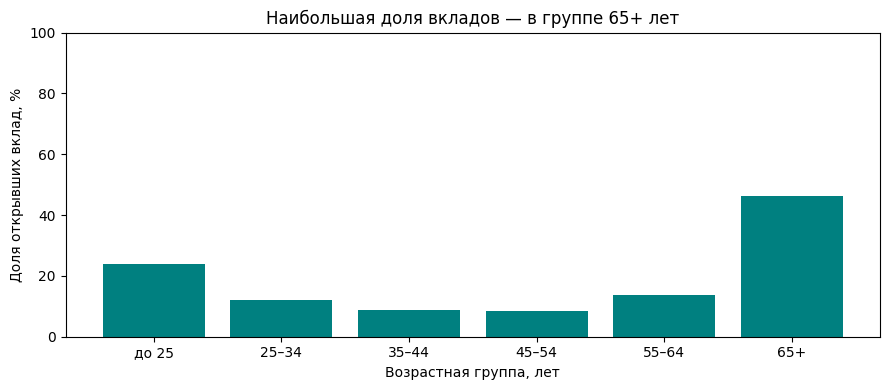

In [297]:
# график 4
age_groups = pd.cut(
    analysis_df["age"],
    bins=[0, 25, 35, 45, 55, 65, 121],
    labels=["до 25", "25–34", "35–44", "45–54", "55–64", "65+"],
    right=False
)

age_stats = (
    analysis_df.groupby(age_groups, observed=True)[TARGET]
    .agg(["count", "mean"])
)

display(age_stats)

top_group = age_stats["mean"].idxmax()

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    age_stats.index.astype(str),
    age_stats["mean"] * 100,
    color="teal"
)

ax.set_title(f"Наибольшая доля вкладов — в группе {top_group} лет")
ax.set_xlabel("Возрастная группа, лет")
ax.set_ylabel("Доля открывших вклад, %")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()


**Что видно на графике 4.** ...

,count,mean
month,,
mar,446.0,0.500000
apr,2098.0,0.199714
may,11031.0,0.064727
jun,4242.0,0.107025
jul,5724.0,0.092418
aug,4971.0,0.103601
sep,459.0,0.448802
oct,557.0,0.436266
nov,3264.0,0.103554


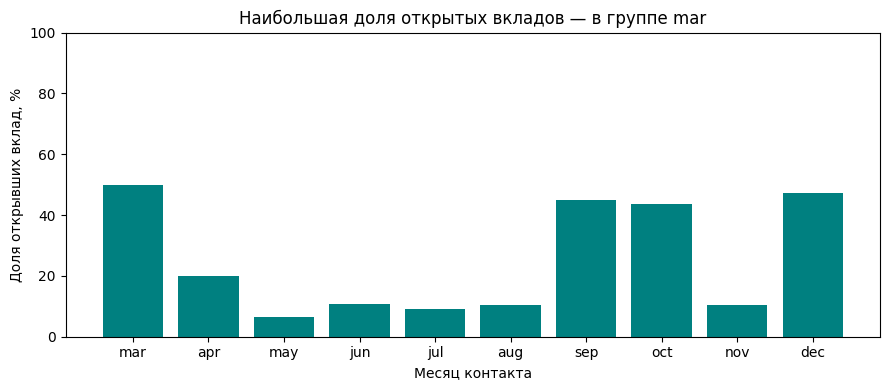

In [298]:
# график 5
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

month_stats = analysis_df.groupby("month")[TARGET].agg(["count", "mean"])

month_stats = month_stats.reindex(month_order).dropna(subset=["mean"])

display(month_stats)

top_month = month_stats["mean"].idxmax()

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    month_stats.index,
    month_stats["mean"] * 100,
    color="teal"
)

ax.set_title(f"Наибольшая доля открытых вкладов — в группе {top_month}")
ax.set_xlabel("Месяц контакта")
ax.set_ylabel("Доля открывших вклад, %")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

**Что видно на графике 5.** ...

**Вывод по EDA.** 3-5 главных находок с числами.

Доля открывших вклад различается между месяцами контакта. При сравнении нужно учитывать разный размер месячных групп. Различия могут быть связаны с составом клиентов и условиями кампаний, поэтому график сам по себе не доказывает влияние сезона.

---
## 8. Функция clean, сторожа и журнал  ·  10 баллов

**Что сделать.**

* собрать все решения разделов 2-6 в одну функцию `clean(raw_table)`: на входе сырая таблица, на выходе чистая;
* проверить, что `clean(raw)` даёт ту же таблицу, что пошаговая очистка;
* сторожа: `assert` на главные правила, например «нет пропусков», «нет невозможных значений»;
* показать журнал: `show_journal()`;
* сохранить чистые данные: `clean_df.to_csv("data/<имя>_clean.csv", index=False)`.

Пример: часть 9 практики, разделы 9.1-9.4.

In [299]:
def clean(raw_table):
    """Сырая таблица на входе, очищенная на выходе."""
    d = raw_table.copy()
    # ваши шаги из разделов 2-6
    d = d.drop_duplicates().copy()

    d["was_previously_contacted"] = (d["pdays"] != 999).astype(int)
    d["days_since_contact"] = d["pdays"].replace(999, np.nan)

    d["attempts_before_call_log"] = np.log1p(d["campaign"] - 1)
    return d

In [300]:
# сравнение с пошаговой очисткой; сторожа assert
clean_df = clean(raw)

assert clean_df.equals(df), "Результат clean(raw) отличается от df"
assert not clean_df.duplicated().any()
assert not check_rules(clean_df).any().any()

other_columns = clean_df.drop(columns=["days_since_contact"])
assert other_columns.notna().all().all()

expected_missing = clean_df["was_previously_contacted"] == 0
actual_missing = clean_df["days_since_contact"].isna()

assert (actual_missing == expected_missing).all(), (
    "Пропуски давности не соответствуют флагу прошлого контакта"
)
assert np.isfinite(clean_df["attempts_before_call_log"]).all(), (
    "В логарифмическом признаке есть NaN или бесконечность"
)

print("Все проверки пройдены.")
print("clean(raw) совпадает с пошаговой обработкой.")
print("Размер очищенной таблицы:", clean_df.shape)

Все проверки пройдены.
clean(raw) совпадает с пошаговой обработкой.
Размер очищенной таблицы: (41176, 24)


In [301]:
show_journal()

,решение,строк
дубли,Удалены полные повторы строк,41176
проверка правил,найдено подозрительных строк: 0. Строки сохран...,41176
скрытые пропуски,unknown сохранены как категории. nonexistent с...,41176
категориальные данные,unknown сохранён отдельной категорией,41176
pdays,Созданы флаг прошлого контакта и давность с Na...,41176
типы и даты,Числа уже имеют числовые типы. Полной даты кон...,41176
выбросы,Допустимые редкие значения сохранены. Для числ...,41176


In [302]:
Path("data").mkdir(exist_ok=True)
clean_df.to_csv("data/banking_clean.csv", index=False)

print("Таблица сохранена: data/banking_clean.csv")

Таблица сохранена: data/banking_clean.csv


---
## 9. Самопроверка и репозиторий  ·  10 баллов

**Самопроверка.** Уберите `#` и запустите. Всё должно быть `OK`, а если где-то `НЕТ` по делу (например, дубли появились после обрезки выбросов, как в части 9 практики), объясните это в выводе.

In [303]:
selfcheck(raw, clean_df, TARGET)

OK   цель есть в чистой таблице
OK   цель без пропусков
OK   цель числом: класс 0 и 1 или число
НЕТ  в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
OK   в журнале минимум 5 решений
строк: было 41188, стало 41176; столбцов: было 21, стало 24


**Репозиторий.**

1. github.com, справа вверху «+», затем «New repository». Имя, например, `midterm-telco`, видимость **Public**, галочку README не ставить.
2. «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит без ошибок. Сохраните её.
3. Скачайте тетрадь: «Файл», затем «Скачать», затем «Скачать .ipynb», имя `project.ipynb`. Скачайте чистый CSV из папки `data` на панели файлов слева.
4. На странице репозитория ссылка «uploading an existing file», перетащите `project.ipynb` и папку `data`, «Commit changes» с подписью «этап 1».
5. Откройте ссылку в режиме инкогнито: тетрадь открывается, графики видны. Сдайте ссылку в LMS.

README на этапе 1 можно сделать черновым: название проекта и одна строка о задаче. Полный README это этап 2.

Пример: часть 9 практики, разделы 9.5-9.6.

---
# Этап 2. Мидтерм, домашка занятия 12

Эти разделы заполняются после занятия 12, в этой же тетради и в том же репозитории. Здесь коротко, что в них будет. Подробности и баллы в ТЗ, примеры в частях 5, 7, 8 и 9 тетради практики занятия 11. Инструменты занятия 12 можно и нужно использовать.

## 10. Новые признаки

Минимум 3 признака из смысла задачи: суммы, доли, флаги, части дат. У каждого одно предложение «зачем». Пример: часть 5, раздел 5.1.

In [304]:
# этап 2

## 11. Категории

Редкие значения в `Other`, флаги через `get_dummies`. Итог: таблица признаков `X` только из чисел, без пропусков. Пример: часть 5, разделы 5.2-5.5.

In [305]:
# этап 2

## 12. Утечка

Таблица «столбец, когда становится известен, берём или нет» для всех подозрительных столбцов. Проверка моделью хотя бы одного подозреваемого: насколько он поднимает качество. Пример: часть 7.

In [306]:
# этап 2

## 13. Baseline

Train и test, пустышка, простая модель на 3-5 признаках, полная модель в `Pipeline`, кросс-валидация на train, test один раз в конце, график-лестница и вывод «модель лучше пустышки на ...». Пример: часть 8.

In [307]:
# этап 2

## 14. Выводы

3-5 пунктов: что узнали о данных, что сработало, что бы сделали дальше.

## 15. README

По шаблону из ТЗ. Журнал и результаты удобно собрать из переменных тетради. Пример: часть 9, раздел 9.4.

In [308]:
# этап 2

## 16. Финальная проверка

`requirements.txt`, «Перезапустить сеанс и выполнить все» без ошибок, тетрадь сохранена с выводами, ссылка открывается в режиме инкогнито. Чек-лист в ТЗ.